In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
borrowers = pd.read_csv("../data/borrower_profiles.csv")
loans = pd.read_csv("../data/loan_applications.csv")

print("Borrower Dataset:", borrowers.shape)
print("Loan Dataset:", loans.shape)

Borrower Dataset: (500, 11)
Loan Dataset: (601, 12)


In [3]:
display(borrowers.head())
display(loans.head())

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869
2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806
3,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928
4,BRW-0005,46,NY,High School,Full-Time,18,44528,715,Own,0,608


,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,LN-00005,BRW-0004,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0


In [4]:
print("========== BORROWER DATASET ==========")

print("\nColumn Names:")
print(borrowers.columns.tolist())

print("\nData Types:")
print(borrowers.dtypes)

print("\n========== LOAN DATASET ==========")

print("\nColumn Names:")
print(loans.columns.tolist())

print("\nData Types:")
print(loans.dtypes)

========== BORROWER DATASET ==========

Column Names:
['borrower_id', 'age', 'state', 'education_level', 'employment_status', 'years_employed', 'annual_income', 'credit_score', 'home_ownership', 'dependents', 'existing_monthly_debt']

Data Types:
borrower_id                str
age                      int64
state                      str
education_level            str
employment_status          str
years_employed           int64
annual_income            int64
credit_score             int64
home_ownership             str
dependents               int64
existing_monthly_debt    int64
dtype: object

========== LOAN DATASET ==========

Column Names:
['loan_id', 'borrower_id', 'application_date', 'loan_purpose', 'loan_amount', 'term_months', 'interest_rate', 'monthly_payment', 'dti_ratio', 'loan_status', 'days_delinquent', 'defaulted']

Data Types:
loan_id                 str
borrower_id             str
application_date        str
loan_purpose            str
loan_amount         float64
term_

In [5]:
print("BORROWER MISSING VALUES")
print(borrowers.isnull().sum())

print("\nLOAN MISSING VALUES")
print(loans.isnull().sum())

BORROWER MISSING VALUES
borrower_id              0
age                      0
state                    0
education_level          0
employment_status        0
years_employed           0
annual_income            0
credit_score             0
home_ownership           0
dependents               0
existing_monthly_debt    0
dtype: int64

LOAN MISSING VALUES
loan_id             0
borrower_id         0
application_date    0
loan_purpose        0
loan_amount         0
term_months         0
interest_rate       0
monthly_payment     0
dti_ratio           0
loan_status         0
days_delinquent     0
defaulted           0
dtype: int64


In [6]:
print("Borrower Duplicates:", borrowers.duplicated().sum())

print("Loan Duplicates:", loans.duplicated().sum())

Borrower Duplicates: 0
Loan Duplicates: 0


## Data Quality and Validation Checks

In [9]:
# 1. Check unique IDs

print("Unique Borrower IDs:", borrowers["borrower_id"].nunique())
print("Unique Loan IDs:", loans["loan_id"].nunique())

# 2. Check unmatched borrower IDs

unmatched = set(loans["borrower_id"]) - set(borrowers["borrower_id"])

print("Unmatched Borrower IDs:", len(unmatched))

# 3. Check default values

print("\nDefault Distribution:")
print(loans["defaulted"].value_counts())

print("\nDefault Percentage:")
print(loans["defaulted"].value_counts(normalize=True) * 100)

# 4. Check loan status

print("\nLoan Status Distribution:")
print(loans["loan_status"].value_counts())

# 5. Check application dates

loans["application_date"] = pd.to_datetime(
    loans["application_date"],
    errors="coerce"
)

print("\nInvalid Dates:", loans["application_date"].isna().sum())

print("Date Range:")
print(loans["application_date"].min())
print(loans["application_date"].max())

# 6. Check unusual numeric values

print("\nDTI Range:")
print(loans["dti_ratio"].min(), loans["dti_ratio"].max())

print("\nCredit Score Range:")
print(borrowers["credit_score"].min(),
      borrowers["credit_score"].max())

print("\nEmployment Years Range:")
print(borrowers["years_employed"].min(),
      borrowers["years_employed"].max())

Unique Borrower IDs: 500
Unique Loan IDs: 601
Unmatched Borrower IDs: 0

Default Distribution:
defaulted
0    455
1    146
Name: count, dtype: int64

Default Percentage:
defaulted
0    75.707155
1    24.292845
Name: proportion, dtype: float64

Loan Status Distribution:
loan_status
Current     239
Default     146
Paid Off    113
Late        103
Name: count, dtype: int64

Invalid Dates: 0
Date Range:
2024-01-02 00:00:00
2025-06-29 00:00:00

DTI Range:
7.6 177.4

Credit Score Range:
528 850

Employment Years Range:
0 35


# Phase 3: Data Cleaning and Joining

## 3.1 Merge Borrower and Loan Datasets


In [10]:
# Merge both datasets using borrower_id

df = loans.merge(
    borrowers,
    on="borrower_id",
    how="left",
    validate="many_to_one"
)

print("Merged Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Merged Dataset Shape: (601, 22)

First 5 Rows:


,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,...,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,...,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,...,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,...,24,CO,High School,Full-Time,4,40188,543,Own,2,869
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,...,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806
4,LN-00005,BRW-0004,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,...,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928


In [11]:
# Check merged dataset

print("Total Loan Applications:", len(loans))
print("Total Merged Records:", len(df))

print("\nMissing Values After Join:")
print(df.isnull().sum())

print("\nDuplicate Loan IDs:")
print(df["loan_id"].duplicated().sum())

print("\nFinal Dataset Columns:")
print(df.columns.tolist())

Total Loan Applications: 601
Total Merged Records: 601

Missing Values After Join:
loan_id                  0
borrower_id              0
application_date         0
loan_purpose             0
loan_amount              0
term_months              0
interest_rate            0
monthly_payment          0
dti_ratio                0
loan_status              0
days_delinquent          0
defaulted                0
age                      0
state                    0
education_level          0
employment_status        0
years_employed           0
annual_income            0
credit_score             0
home_ownership           0
dependents               0
existing_monthly_debt    0
dtype: int64

Duplicate Loan IDs:
0

Final Dataset Columns:
['loan_id', 'borrower_id', 'application_date', 'loan_purpose', 'loan_amount', 'term_months', 'interest_rate', 'monthly_payment', 'dti_ratio', 'loan_status', 'days_delinquent', 'defaulted', 'age', 'state', 'education_level', 'employment_status', 'years_employed', 

In [12]:
import os

os.makedirs("../data/processed", exist_ok=True)

df.to_csv(
    "../data/processed/loan_default_merged.csv",
    index=False
)

print("Merged dataset saved successfully!")

Merged dataset saved successfully!


# Phase 4: SQL Analysis

## 4.1 Creating SQLite Database

In [13]:
import sqlite3
import os

# Create database connection
os.makedirs("../data", exist_ok=True)

conn = sqlite3.connect("../data/loan_analysis.db")

# Prepare data for SQL
sql_df = df.copy()

sql_df["application_date"] = (
    sql_df["application_date"].astype(str)
)

# Save merged dataset as SQL table
sql_df.to_sql(
    "loan_data",
    conn,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully!")

SQLite database created successfully!


In [14]:
# Check total records in SQL table

result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM loan_data",
    conn
)

display(result)

,total_records
0,601


In [15]:
columns = pd.read_sql_query(
    "PRAGMA table_info(loan_data)",
    conn
)

display(columns)

,cid,name,type,notnull,dflt_value,pk
0,0,loan_id,TEXT,0,None,0
1,1,borrower_id,TEXT,0,None,0
2,2,application_date,TEXT,0,None,0
3,3,loan_purpose,TEXT,0,None,0
4,4,loan_amount,REAL,0,None,0
5,5,term_months,INTEGER,0,None,0
6,6,interest_rate,REAL,0,None,0
7,7,monthly_payment,REAL,0,None,0
8,8,dti_ratio,REAL,0,None,0
9,9,loan_status,TEXT,0,None,0


## 4.2 Overall Loan Default Rate

In [16]:
query = """
SELECT
    COUNT(*) AS total_loans,
    SUM(defaulted) AS defaulted_loans,

    ROUND(
        AVG(defaulted) * 100, 2
    ) AS default_rate,

    12.0 AS target_default_rate,

    ROUND(
        (AVG(defaulted) * 100) - 12.0, 2
    ) AS above_target_percentage_points

FROM loan_data;
"""

result = pd.read_sql_query(query, conn)

display(result)

,total_loans,defaulted_loans,default_rate,target_default_rate,above_target_percentage_points
0,601,146,24.29,12.0,12.29


## 4.3 Default Rate by Credit Score Range

In [17]:
query = """
SELECT
    CASE
        WHEN credit_score BETWEEN 520 AND 599 THEN '520-599'
        WHEN credit_score BETWEEN 600 AND 649 THEN '600-649'
        WHEN credit_score BETWEEN 650 AND 699 THEN '650-699'
        WHEN credit_score BETWEEN 700 AND 749 THEN '700-749'
        WHEN credit_score >= 750 THEN '750+'
        ELSE 'Below 520'
    END AS credit_score_bucket,

    COUNT(*) AS total_loans,

    SUM(defaulted) AS defaulted_loans,

    ROUND(AVG(defaulted) * 100, 2) AS default_rate

FROM loan_data

GROUP BY credit_score_bucket

ORDER BY MIN(credit_score);
"""

credit_analysis = pd.read_sql_query(query, conn)

display(credit_analysis)

,credit_score_bucket,total_loans,defaulted_loans,default_rate
0,520-599,116,57,49.14
1,600-649,93,27,29.03
2,650-699,75,21,28.00
3,700-749,86,14,16.28
4,750+,231,27,11.69


In [18]:
credit_analysis.to_csv(
    "../reports/credit_score_analysis.csv",
    index=False
)

In [19]:
os.makedirs("../reports", exist_ok=True)

## 4.4 Debt-to-Income Ratio Analysis

In [20]:
query = """
SELECT
    COUNT(*) AS total_loans,
    ROUND(MIN(dti_ratio), 2) AS minimum_dti,
    ROUND(MAX(dti_ratio), 2) AS maximum_dti,
    ROUND(AVG(dti_ratio), 2) AS average_dti,
    ROUND(AVG(defaulted) * 100, 2) AS overall_default_rate
FROM loan_data;
"""

dti_summary = pd.read_sql_query(query, conn)

display(dti_summary)

,total_loans,minimum_dti,maximum_dti,average_dti,overall_default_rate
0,601,7.6,177.4,49.68,24.29


In [21]:
query = """
SELECT
    CASE
        WHEN dti_ratio < 20 THEN 'Below 20'
        WHEN dti_ratio < 35 THEN '20-34.9'
        WHEN dti_ratio < 50 THEN '35-49.9'
        WHEN dti_ratio < 65 THEN '50-64.9'
        ELSE '65+'
    END AS dti_bucket,

    COUNT(*) AS total_loans,

    SUM(defaulted) AS defaulted_loans,

    ROUND(AVG(defaulted) * 100, 2) AS default_rate

FROM loan_data

GROUP BY dti_bucket

ORDER BY MIN(dti_ratio);
"""

dti_analysis = pd.read_sql_query(query, conn)

display(dti_analysis)

,dti_bucket,total_loans,defaulted_loans,default_rate
0,Below 20,48,8,16.67
1,20-34.9,132,14,10.61
2,35-49.9,150,31,20.67
3,50-64.9,143,47,32.87
4,65+,128,46,35.94


In [22]:
dti_analysis.to_csv(
    "../reports/dti_analysis.csv",
    index=False
)

## 4.5 Default Rate by Loan Purpose

In [23]:
query = """
SELECT
    loan_purpose,

    COUNT(*) AS total_loans,

    SUM(defaulted) AS defaulted_loans,

    ROUND(
        AVG(defaulted) * 100, 2
    ) AS default_rate,

    ROUND(
        AVG(loan_amount), 2
    ) AS average_loan_amount

FROM loan_data

GROUP BY loan_purpose

ORDER BY default_rate DESC;
"""

purpose_analysis = pd.read_sql_query(query, conn)

display(purpose_analysis)

,loan_purpose,total_loans,defaulted_loans,default_rate,average_loan_amount
0,Wedding,56,18,32.14,21892.86
1,Home Improvement,70,20,28.57,23407.14
2,Auto Loan,59,16,27.12,19554.24
3,Business Loan,58,14,24.14,21013.79
4,Education,53,12,22.64,19847.17
5,Vacation,62,14,22.58,24477.42
6,Major Purchase,68,15,22.06,23164.71
7,Debt Consolidation,51,11,21.57,22756.86
8,Moving,56,12,21.43,21300.00
9,Medical Expenses,68,14,20.59,23176.47


In [24]:
purpose_analysis.to_csv(
    "../reports/loan_purpose_analysis.csv",
    index=False
)

## 4.6 Average Loan Amount: Defaulted vs Non-Defaulted

In [25]:
query = """
SELECT
    CASE
        WHEN defaulted = 1 THEN 'Defaulted'
        ELSE 'Non-Defaulted'
    END AS loan_group,

    COUNT(*) AS total_loans,

    ROUND(AVG(loan_amount), 2) AS average_loan_amount,

    ROUND(MIN(loan_amount), 2) AS minimum_loan_amount,

    ROUND(MAX(loan_amount), 2) AS maximum_loan_amount

FROM loan_data

GROUP BY defaulted;
"""

loan_amount_analysis = pd.read_sql_query(query, conn)

display(loan_amount_analysis)

,loan_group,total_loans,average_loan_amount,minimum_loan_amount,maximum_loan_amount
0,Non-Defaulted,455,22012.75,2000.0,49800.0
1,Defaulted,146,22570.55,2400.0,49700.0


In [27]:
loan_amount_analysis.to_csv(
    "../reports/loan_amount_comparison.csv",
    index=False
)

## 4.7 Statistical Test: Loan Amount vs Default Status

In [28]:
from scipy import stats
import numpy as np

# Separate loan amounts into two groups

defaulted_amounts = df.loc[
    df["defaulted"] == 1, "loan_amount"
]

non_defaulted_amounts = df.loc[
    df["defaulted"] == 0, "loan_amount"
]

# Calculate average loan amounts

default_mean = defaulted_amounts.mean()
non_default_mean = non_defaulted_amounts.mean()

# Calculate difference

difference = default_mean - non_default_mean

# Perform Welch's t-test

t_stat, p_value = stats.ttest_ind(
    defaulted_amounts,
    non_defaulted_amounts,
    equal_var=False
)

print("Defaulted Average Loan:", round(default_mean, 2))
print("Non-Defaulted Average Loan:", round(non_default_mean, 2))
print("Difference:", round(difference, 2))

print("T-Statistic:", round(t_stat, 4))
print("P-Value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")

Defaulted Average Loan: 22570.55
Non-Defaulted Average Loan: 22012.75
Difference: 557.8
T-Statistic: 0.4446
P-Value: 0.657
Result: No statistically significant difference


## 4.8 Default Rate by Employment Status

In [29]:
query = """
SELECT
    employment_status,

    COUNT(*) AS total_loans,

    SUM(defaulted) AS defaulted_loans,

    ROUND(
        AVG(defaulted) * 100, 2
    ) AS default_rate

FROM loan_data

GROUP BY employment_status

ORDER BY default_rate DESC;
"""

employment_analysis = pd.read_sql_query(query, conn)

display(employment_analysis)

,employment_status,total_loans,defaulted_loans,default_rate
0,Part-Time,65,18,27.69
1,Self-Employed,105,26,24.76
2,Full-Time,305,73,23.93
3,Retired,60,14,23.33
4,Contract,66,15,22.73


## 4.9 Default Rate by Years Employed

In [30]:
query = """
SELECT
    CASE
        WHEN years_employed < 2 THEN 'Less than 2 years'
        WHEN years_employed < 5 THEN '2-4 years'
        WHEN years_employed < 10 THEN '5-9 years'
        ELSE '10+ years'
    END AS employment_tenure,

    COUNT(*) AS total_loans,

    SUM(defaulted) AS defaulted_loans,

    ROUND(
        AVG(defaulted) * 100, 2
    ) AS default_rate

FROM loan_data

GROUP BY employment_tenure

ORDER BY MIN(years_employed);
"""

tenure_analysis = pd.read_sql_query(query, conn)

display(tenure_analysis)

,employment_tenure,total_loans,defaulted_loans,default_rate
0,Less than 2 years,84,29,34.52
1,2-4 years,114,20,17.54
2,5-9 years,126,33,26.19
3,10+ years,277,64,23.10


In [31]:
employment_analysis.to_csv(
    "../reports/employment_status_analysis.csv",
    index=False
)

tenure_analysis.to_csv(
    "../reports/employment_tenure_analysis.csv",
    index=False
)

## 4.10 Statistical Test: Employment Tenure vs Default

In [32]:
from scipy.stats import chi2_contingency

# Create two employment groups

less_than_2 = df[df["years_employed"] < 2]
two_or_more = df[df["years_employed"] >= 2]

# Create contingency table

contingency_table = [
    [
        less_than_2["defaulted"].sum(),
        (less_than_2["defaulted"] == 0).sum()
    ],
    [
        two_or_more["defaulted"].sum(),
        (two_or_more["defaulted"] == 0).sum()
    ]
]

# Perform Chi-Square test

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Calculate default rates

rate_less_2 = less_than_2["defaulted"].mean() * 100
rate_two_plus = two_or_more["defaulted"].mean() * 100

print("Less than 2 Years Default Rate:", round(rate_less_2, 2), "%")
print("2+ Years Default Rate:", round(rate_two_plus, 2), "%")

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", round(p_value, 4))

print("Risk Ratio:", round(rate_less_2 / rate_two_plus, 2))

if p_value < 0.05:
    print("Result: Statistically significant association")
else:
    print("Result: No statistically significant association")

Less than 2 Years Default Rate: 34.52 %
2+ Years Default Rate: 22.63 %
Chi-Square Statistic: 4.9297
P-Value: 0.0264
Risk Ratio: 1.53
Result: Statistically significant association


# Phase 5: Correlation Analysis

## 5.1 Correlation Between Numeric Variables and Loan Defaults

In [33]:
# Select numeric variables

numeric_columns = [
    "credit_score",
    "dti_ratio",
    "annual_income",
    "loan_amount",
    "interest_rate",
    "years_employed",
    "defaulted"
]

# Create correlation matrix

correlation_matrix = df[numeric_columns].corr(
    method="pearson"
)

# Display correlation with defaulted

default_correlation = (
    correlation_matrix["defaulted"]
    .drop("defaulted")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with Loan Default:\n")

display(default_correlation.to_frame(
    name="correlation_with_default"
))

Correlation with Loan Default:



,correlation_with_default
credit_score,-0.286394
interest_rate,0.198930
dti_ratio,0.192454
annual_income,-0.081546
loan_amount,0.018116
years_employed,-0.007199


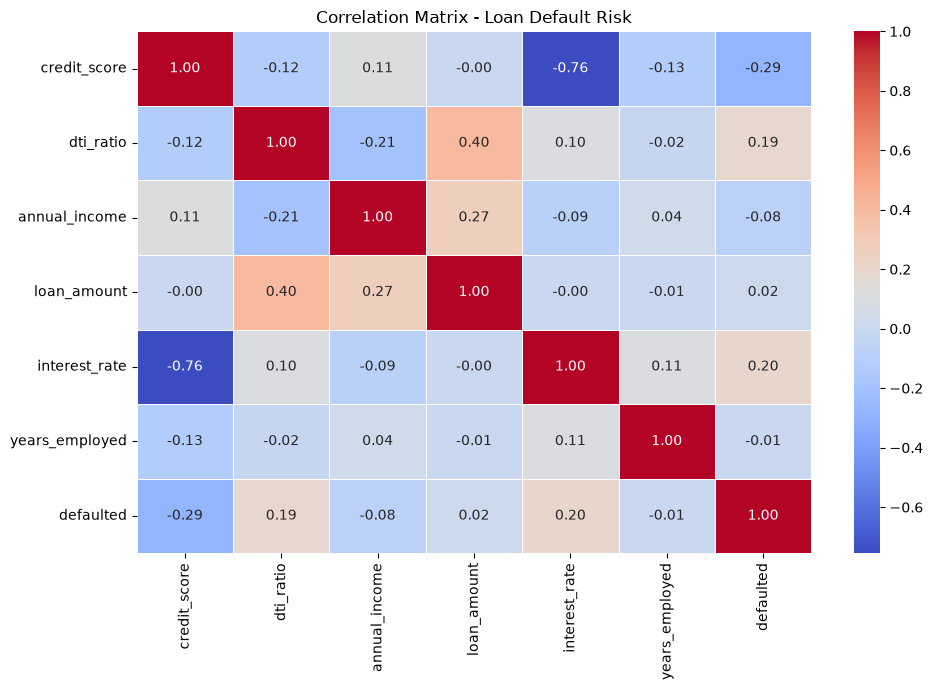

In [34]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix - Loan Default Risk")

plt.tight_layout()

plt.show()

In [35]:
os.makedirs("../reports", exist_ok=True)

default_correlation.to_csv(
    "../reports/default_correlation.csv"
)

correlation_matrix.to_csv(
    "../reports/correlation_matrix.csv"
)

print("Correlation reports saved successfully!")

Correlation reports saved successfully!


# Phase 6: Data Visualization

## 6.1 Default Rate by Credit Score Range

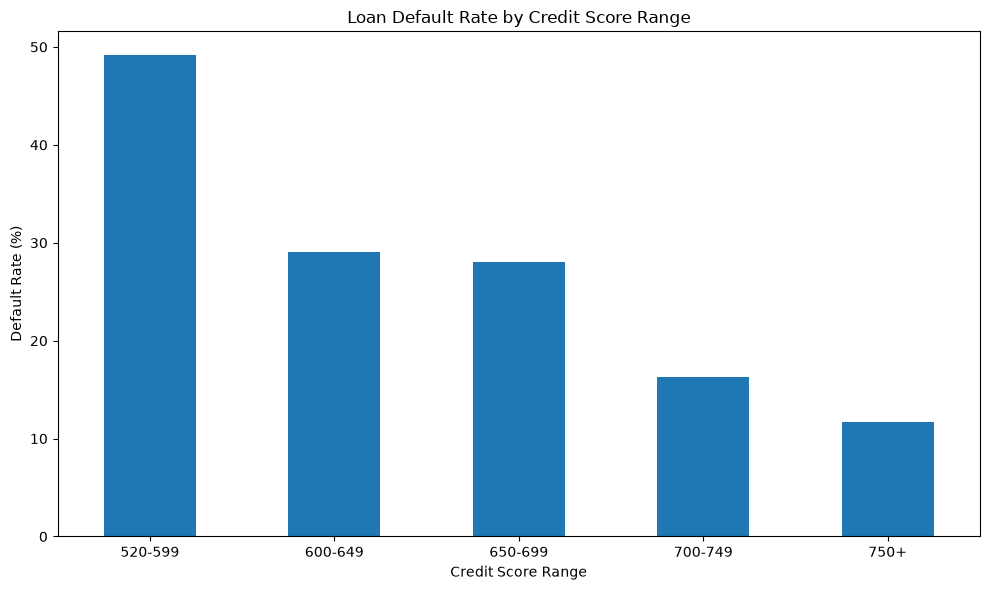

In [36]:
# Create credit score categories

df["credit_score_bucket"] = pd.cut(
    df["credit_score"],
    bins=[519, 599, 649, 699, 749, float("inf")],
    labels=["520-599", "600-649", "650-699", "700-749", "750+"]
)

# Calculate default rate

credit_chart = (
    df.groupby("credit_score_bucket", observed=False)["defaulted"]
    .mean() * 100
)

# Create chart

plt.figure(figsize=(10, 6))

credit_chart.plot(kind="bar")

plt.title("Loan Default Rate by Credit Score Range")
plt.xlabel("Credit Score Range")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 6.2 DTI Ratio vs Loan Default

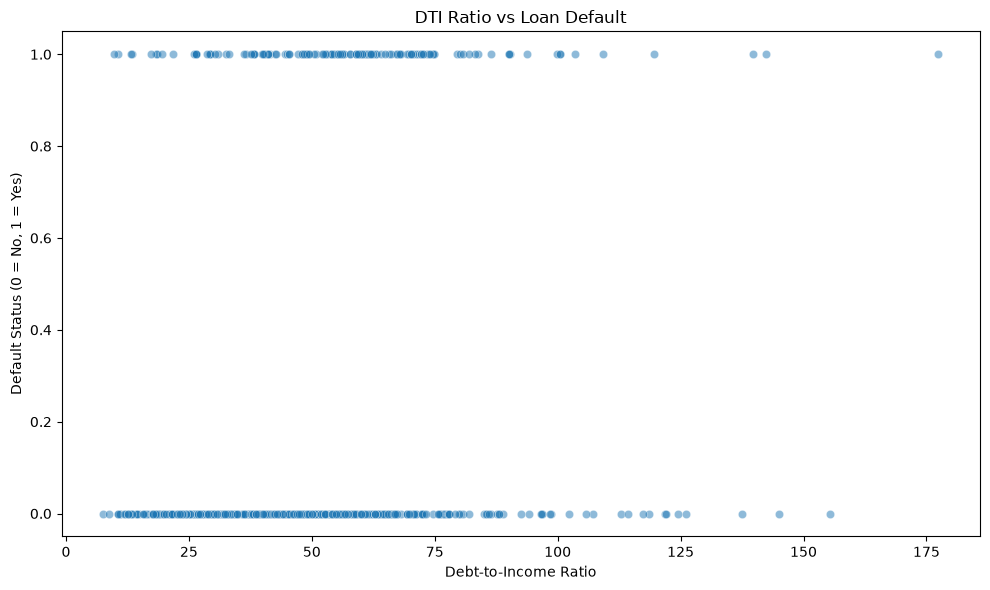

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="dti_ratio",
    y="defaulted",
    alpha=0.5
)

plt.title("DTI Ratio vs Loan Default")
plt.xlabel("Debt-to-Income Ratio")
plt.ylabel("Default Status (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

## 6.3 Default Rate by Loan Purpose

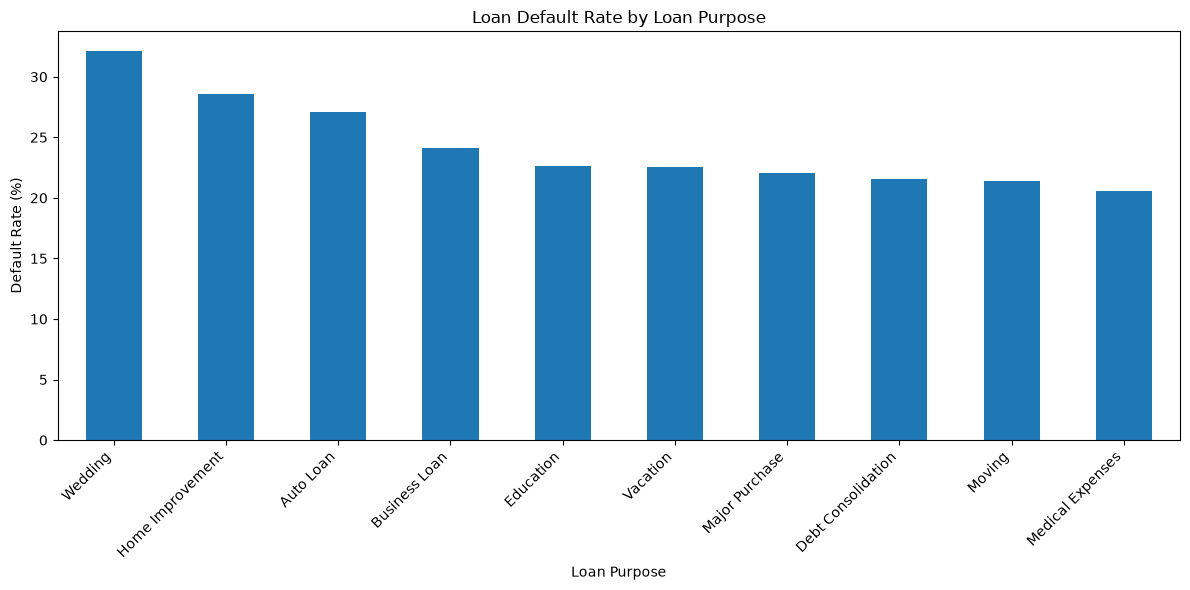

In [38]:
purpose_chart = (
    df.groupby("loan_purpose")["defaulted"]
    .mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(12, 6))

purpose_chart.plot(kind="bar")

plt.title("Loan Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## 6.4 Default Rate by Employment Tenure

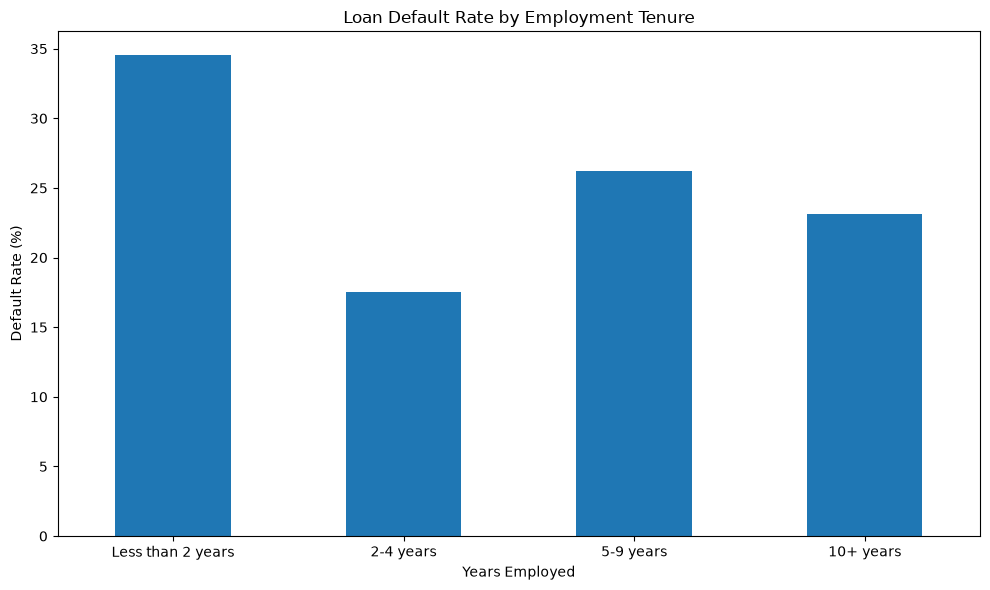

In [39]:
df["employment_tenure"] = pd.cut(
    df["years_employed"],
    bins=[-1, 1, 4, 9, float("inf")],
    labels=[
        "Less than 2 years",
        "2-4 years",
        "5-9 years",
        "10+ years"
    ]
)

tenure_chart = (
    df.groupby("employment_tenure", observed=False)["defaulted"]
    .mean() * 100
)

plt.figure(figsize=(10, 6))

tenure_chart.plot(kind="bar")

plt.title("Loan Default Rate by Employment Tenure")
plt.xlabel("Years Employed")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [40]:
os.makedirs("../reports/charts", exist_ok=True)

credit_chart.plot(kind="bar", figsize=(10, 6))
plt.title("Default Rate by Credit Score")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.savefig("../reports/charts/credit_score_default.png", dpi=300)
plt.close()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="dti_ratio", y="defaulted", alpha=0.5)
plt.title("DTI vs Default")
plt.tight_layout()
plt.savefig("../reports/charts/dti_default.png", dpi=300)
plt.close()

plt.figure(figsize=(12, 6))
purpose_chart.plot(kind="bar")
plt.title("Default Rate by Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.savefig("../reports/charts/loan_purpose_default.png", dpi=300)
plt.close()

plt.figure(figsize=(10, 6))
tenure_chart.plot(kind="bar")
plt.title("Default Rate by Employment Tenure")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.savefig("../reports/charts/employment_tenure_default.png", dpi=300)
plt.close()

print("All charts saved successfully!")

All charts saved successfully!


In [41]:
# Select important numerical columns
numeric_cols = [
    "age",
    "years_employed",
    "annual_income",
    "credit_score",
    "existing_monthly_debt",
    "loan_amount",
    "interest_rate",
    "monthly_payment",
    "dti_ratio",
    "defaulted"
]

# Calculate correlation
correlation_matrix = df[numeric_cols].corr()

# Show correlation with defaulted
default_correlation = correlation_matrix["defaulted"].sort_values(
    ascending=False
)

print(default_correlation)

defaulted                1.000000
interest_rate            0.198930
dti_ratio                0.192454
existing_monthly_debt    0.083325
monthly_payment          0.061867
loan_amount              0.018116
age                     -0.006085
years_employed          -0.007199
annual_income           -0.081546
credit_score            -0.286394
Name: defaulted, dtype: float64


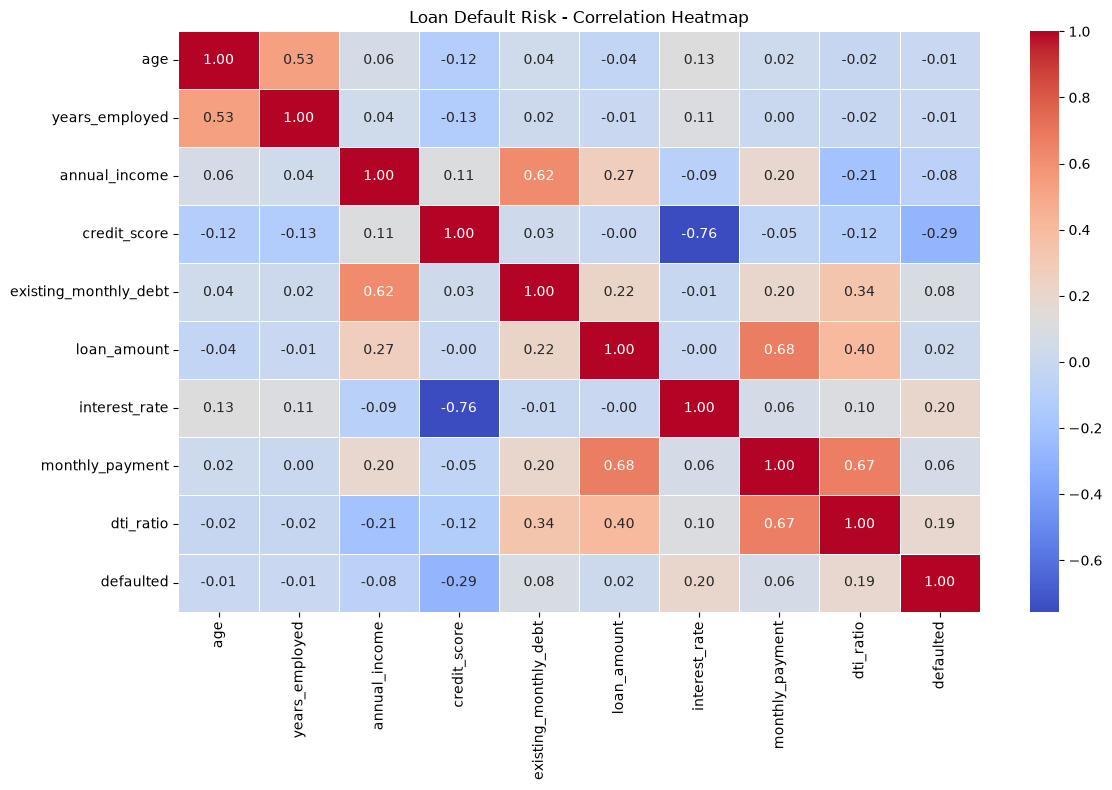

In [42]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Loan Default Risk - Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "../reports/correlation_heatmap.png",
    dpi=300
)

plt.show()

In [43]:
# Credit Score Threshold Analysis

credit_thresholds = [600, 625, 650, 675, 700, 725, 750]

credit_results = []

for threshold in credit_thresholds:

    eligible = df[df["credit_score"] >= threshold]

    credit_results.append({
        "Credit Score Cutoff": threshold,
        "Eligible Loans": len(eligible),
        "Approval Rate (%)": round(len(eligible) / len(df) * 100, 2),
        "Defaults Among Eligible": int(eligible["defaulted"].sum()),
        "Default Rate (%)": round(eligible["defaulted"].mean() * 100, 2)
    })

credit_threshold_df = pd.DataFrame(credit_results)

print(credit_threshold_df)

   Credit Score Cutoff  Eligible Loans  Approval Rate (%)  \
0                  600             485              80.70   
1                  625             431              71.71   
2                  650             392              65.22   
3                  675             352              58.57   
4                  700             317              52.75   
5                  725             275              45.76   
6                  750             231              38.44   

   Defaults Among Eligible  Default Rate (%)  
0                       89             18.35  
1                       68             15.78  
2                       62             15.82  
3                       51             14.49  
4                       41             12.93  
5                       37             13.45  
6                       27             11.69  


In [44]:
# DTI Threshold Analysis

dti_thresholds = [35, 40, 45, 50, 55, 60]

dti_results = []

for threshold in dti_thresholds:

    eligible = df[df["dti_ratio"] <= threshold]

    dti_results.append({
        "DTI Cutoff": threshold,
        "Eligible Loans": len(eligible),
        "Approval Rate (%)": round(len(eligible) / len(df) * 100, 2),
        "Defaults Among Eligible": int(eligible["defaulted"].sum()),
        "Default Rate (%)": round(eligible["defaulted"].mean() * 100, 2)
    })

dti_threshold_df = pd.DataFrame(dti_results)

print(dti_threshold_df)

   DTI Cutoff  Eligible Loans  Approval Rate (%)  Defaults Among Eligible  \
0          35             181              30.12                       22   
1          40             237              39.43                       31   
2          45             271              45.09                       41   
3          50             331              55.07                       53   
4          55             382              63.56                       65   
5          60             430              71.55                       85   

   Default Rate (%)  
0             12.15  
1             13.08  
2             15.13  
3             16.01  
4             17.02  
5             19.77  


In [45]:
# Combined Credit Score and DTI Threshold Analysis

credit_cutoffs = [650, 700, 750]
dti_cutoffs = [35, 40, 45, 50, 55]

combined_results = []

for credit_cutoff in credit_cutoffs:
    for dti_cutoff in dti_cutoffs:

        eligible = df[
            (df["credit_score"] >= credit_cutoff) &
            (df["dti_ratio"] <= dti_cutoff)
        ]

        combined_results.append({
            "Credit Score Cutoff": credit_cutoff,
            "DTI Cutoff": dti_cutoff,
            "Eligible Loans": len(eligible),
            "Approval Rate (%)": round(len(eligible) / len(df) * 100, 2),
            "Defaults Among Eligible": int(eligible["defaulted"].sum()),
            "Default Rate (%)": round(eligible["defaulted"].mean() * 100, 2)
        })

combined_df = pd.DataFrame(combined_results)

print(combined_df.to_string(index=False))

 Credit Score Cutoff  DTI Cutoff  Eligible Loans  Approval Rate (%)  Defaults Among Eligible  Default Rate (%)
                 650          35             128              21.30                       12              9.38
                 650          40             168              27.95                       17             10.12
                 650          45             188              31.28                       22             11.70
                 650          50             231              38.44                       28             12.12
                 650          55             266              44.26                       33             12.41
                 700          35             105              17.47                        9              8.57
                 700          40             141              23.46                       14              9.93
                 700          45             155              25.79                       16             10.32
 

# Business Recommendations

Based on the analysis of 601 loan applications, the following recommendations are proposed for Horizon Financial Group:

1. **Improve Credit Score Screening:** Applicants with credit scores below 600 showed substantially higher default rates. Additional creditworthiness checks should be considered for this group.

2. **Strengthen DTI Assessment:** Applicants with DTI ratios above 50 showed higher default rates. The bank should conduct additional affordability assessments for applicants with high debt burdens.

3. **Consider Employment Stability:** Applicants with less than two years of employment had a 34.52% default rate, compared with 22.63% for applicants with two or more years of employment. Employment tenure should be considered as one of several risk indicators.

4. **Monitor Loan Purpose:** Wedding loans had the highest observed default rate at 32.14%. The bank should monitor default trends across loan purposes.

5. **Test Combined Screening Criteria:** A historical screening combination of credit score ≥700 and DTI ≤55 produced a 10.55% default rate among 218 eligible loans. This rule may be evaluated in a controlled pilot.

6. **Validate Before Implementation:** These findings are based on historical data and do not establish causation. Any proposed lending criteria should be tested on new, out-of-time data before implementation.

## Overall Conclusion

The analysis found an overall loan default rate of 24.29%, which is 12.29 percentage points above the bank's 12% target. Credit score, DTI ratio, interest rate, and employment tenure provide useful indicators for understanding default risk. A combination of improved borrower screening, affordability assessment, and ongoing portfolio monitoring may help the bank manage credit risk.

# Loan Default Risk Analysis
**Client:** Horizon Financial Group  
**Project Type:** Data Analytics – Credit Risk Analysis  
**Tools:** Python, Pandas, SQL, SQLite, Matplotlib, Seaborn, Statistical Analysis

## 1. Executive Summary

Horizon Financial Group issued 601 personal loans during 2024–2025. The analysis identified an overall default rate of **24.29%**, significantly above the bank's target of 12%.

The project examined borrower demographics, credit scores, debt-to-income ratios, loan characteristics, and employment stability to identify patterns associated with loan defaults.

The findings suggest that credit score, DTI ratio, interest rate, and employment tenure are useful indicators for understanding loan default risk.

## 2. Project Objectives

- Calculate the overall loan default rate.
- Identify high-risk credit score groups.
- Examine the relationship between DTI and loan defaults.
- Analyze default rates across loan purposes.
- Compare loan amounts for defaulted and non-defaulted loans.
- Investigate employment status and employment tenure.
- Evaluate potential credit score and DTI screening thresholds.

## 3. Data Preparation

Two datasets were used:

- Borrower Profiles
- Loan Applications

The datasets were joined using `borrower_id`.

**Final dataset:**
- 500 unique borrowers
- 601 loan applications
- 22 columns after merging
- No missing values identified
- No duplicate loan IDs
- No unmatched borrower IDs

## 4. Key Findings

### Overall Default Performance

| Metric | Result |
|---|---:|
| Total loans | 601 |
| Defaulted loans | 146 |
| Overall default rate | 24.29% |
| Target default rate | 12% |
| Difference | 12.29 percentage points |

### Credit Score Analysis

- 520–599: 49.14% default rate
- 600–649: 29.03%
- 650–699: 28.00%
- 700–749: 16.28%
- 750+: 11.69%

Lower credit score groups showed higher observed default rates.

### DTI Analysis

- DTI below 20: 16.67%
- DTI 20–34.9: 10.61%
- DTI 35–49.9: 20.67%
- DTI 50–64.9: 32.87%
- DTI 65+: 35.94%

Higher DTI groups generally showed higher default rates.

### Loan Purpose Analysis

- Wedding: 32.14% – highest
- Home Improvement: 28.57%
- Auto Loan: 27.12%
- Medical Expenses: 20.59% – lowest

### Loan Amount Statistical Test

| Metric | Result |
|---|---:|
| Defaulted loan average | $22,570.55 |
| Non-defaulted loan average | $22,012.75 |
| Mean difference | $557.80 |
| Welch's t-test p-value | 0.657 |

The difference was not statistically significant at the 5% significance level.

### Employment Tenure Analysis

| Group | Default Rate |
|---|---:|
| Less than 2 years | 34.52% |
| 2 or more years | 22.63% |

Chi-square test:
- Statistic: 4.9297
- P-value: 0.0264
- Risk ratio: 1.53

The analysis found a statistically significant association between employment tenure and loan defaults.

### Correlation Analysis

The strongest observed correlations with default status were:

- Credit score: -0.286
- Interest rate: +0.199
- DTI ratio: +0.192

These are associations, not proof of causation.

## 5. Screening Threshold Analysis

A combined historical screening scenario was evaluated:

**Credit Score ≥700 and DTI ≤55**

| Metric | Result |
|---|---:|
| Eligible loans | 218 |
| Historical coverage | 36.27% |
| Defaults among eligible loans | 23 |
| Default rate among eligible loans | 10.55% |

This combination is a potential pilot candidate, not a validated lending policy.

## 6. Business Recommendations

1. Introduce additional creditworthiness checks for applicants with low credit scores.
2. Conduct stronger affordability assessments for applicants with high DTI ratios.
3. Consider employment stability as one of several risk indicators.
4. Monitor default trends across loan purposes.
5. Pilot combined credit score and DTI screening criteria.
6. Validate all proposed rules using new, out-of-time data before implementation.

## 7. Limitations

- The analysis uses historical data and does not establish causation.
- Some borrowers have multiple loans, so loan-level observations may not be independent.
- The DTI maximum of 177.4 requires validation against the original data definition.
- Threshold simulations are historical comparisons, not predictions of future defaults.
- Further validation is needed before operational use.

## 8. Conclusion

The analysis found that Horizon Financial Group's default rate was 24.29%, more than twice its 12% target.

Credit score, DTI ratio, interest rate, and employment tenure showed useful relationships with default risk. Combining borrower indicators may help the bank improve its risk-screening process, provided that proposed criteria are validated before implementation.

## 9. Technical Skills Demonstrated

- Data cleaning and preprocessing
- Data merging using Pandas
- SQL queries and aggregation
- SQLite database management
- Exploratory Data Analysis
- Data visualization
- Correlation analysis
- Hypothesis testing
- Chi-square test
- Welch's independent t-test
- Business recommendations and reporting